In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense,Dropout

In [3]:
from skimage.transform import resize
from skimage.io import imread

In [4]:
os.listdir("/content/drive/MyDrive/Brain Tumor")

['Training', 'Testing']

In [5]:
os.listdir("/content/drive/MyDrive/Brain Tumor/Testing")

['meningioma', 'notumor', 'pituitary', 'glioma']

In [6]:
os.listdir("/content/drive/MyDrive/Brain Tumor/Training")

['meningioma', 'notumor', 'glioma', 'pituitary']

In [7]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Testing/glioma"))

400

In [8]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Testing/meningioma"))

400

In [9]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Testing/notumor"))

400

In [10]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Testing/pituitary"))

400

In [11]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Training/glioma"))

1400

In [12]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Training/meningioma"))

1400

In [13]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Training/notumor"))

1400

In [14]:
len(os.listdir("/content/drive/MyDrive/Brain Tumor/Training/pituitary"))

1400

In [15]:
xtrain=[]
ytrain=[]

In [16]:
datadir="/content/drive/MyDrive/Brain Tumor/Training"

In [17]:
categories=sorted(["glioma","meningioma","notumor","pituitary"])

In [18]:
for i in categories:
  print(i)
  path=os.path.join(datadir,i)
  for j in os.listdir(path):
    img_a=imread(os.path.join(path,j))
    img_r=resize(img_a,(150,150,1))
    xtrain.append(img_r)
    ytrain.append(categories.index(i))
  print("done")

glioma
done
meningioma
done
notumor
done
pituitary
done


In [19]:
xtest=[]
ytest=[]

In [20]:
datadir1="/content/drive/MyDrive/Brain Tumor/Testing"

In [21]:
categories1=sorted(["glioma","meningioma","notumor","pituitary"])

In [22]:
for x in categories1:
  print(x)
  path=os.path.join(datadir1,x)
  for y in os.listdir(path):
    img_a1=imread(os.path.join(path,y))
    img_r1=resize(img_a1,(150,150,1))
    xtest.append(img_r1)
    ytest.append(categories1.index(x))
  print("done")

glioma
done
meningioma
done
notumor
done
pituitary
done


In [23]:
xtrain=np.array(xtrain)
ytrain=np.array(ytrain)

xtest=np.array(xtest)
ytest=np.array(ytest)

In [24]:
model=Sequential()
model.add(Conv2D(32,(3,3),activation="relu",input_shape=(150,150,1)))
model.add(MaxPool2D(2,2))
model.add(Conv2D(64,(3,3),activation="relu"))
model.add(MaxPool2D(2,2))
model.add(Flatten())
model.add(Dense(128,activation="relu"))
model.add(Dense(64,activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(4,activation="softmax"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [25]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [26]:
# model.fit(xtrain,ytrain,epochs=15,batch_size=200)

Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 19s 193ms/step - accuracy: 0.5446 - loss: 1.0139 - val_accuracy: 0.6644 - val_loss: 0.9331
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 125ms/step - accuracy: 0.7613 - loss: 0.5978 - val_accuracy: 0.7487 - val_loss: 0.7642
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 125ms/step - accuracy: 0.8230 - loss: 0.4469 - val_accuracy: 0.7756 - val_loss: 0.7438
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step - accuracy: 0.8552 - loss: 0.3655 - val_accuracy: 0.7725 - val_loss: 0.8824
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - accuracy: 0.8927 - loss: 0.2880 - val_accuracy: 0.8194 - val_loss: 0.6776
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.9230 - loss: 0.2148 - val_accuracy: 0.8331 - val_loss: 0.7265
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.9352 - loss: 0.1713 - val_accuracy: 0.8519 - val_loss: 0.6889
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.9464 - loss: 0.1454 - val_accuracy: 0

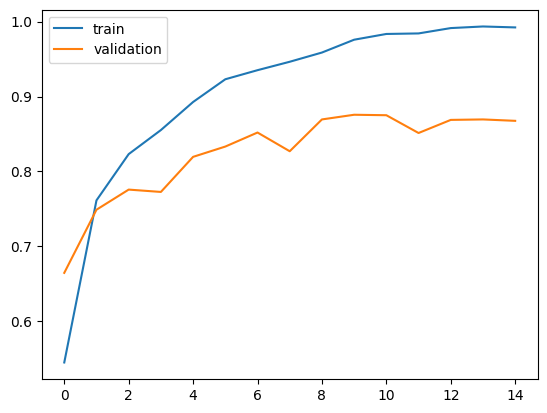

In [27]:
import matplotlib.pyplot as plt
history=model.fit(xtrain,ytrain,validation_data=(xtest,ytest), epochs=15,batch_size=200)
plt.plot(history.history['accuracy'],label="train")
plt.plot(history.history['val_accuracy'],label="validation")
plt.legend()
plt.show()

In [28]:
photo='/content/drive/MyDrive/Brain Tumor/Training/notumor/Tr-no_1098.jpg'


In [ ]:
img=imread(photo)
img

In [35]:
print(img.shape)
print(img.ndim)

(1, 1, 1, 150, 150, 1, 1)
7


In [ ]:
img=resize(img,(150,150))
img= np.expand_dims(img, axis=-1)
img= np.expand_dims(img, axis=0)
img=img/255.0
pred = model.predict(img)[0][0]

In [ ]:
pred=model.predict(imgres)
pred

In [ ]:
res=np.argmax(pred)
res

In [ ]:
categories[0]